# 04 · Main analysis: can rain, terrain and rivers explain unusual flooding?

**Start here.** This notebook holds every result in the paper. It runs from one small file, `data_small/model_table.parquet` (built by notebooks 00 to 03), in about 15 to 30 minutes on a normal CPU, or 2 minutes with `FAST = True`.

**The question.** Flooding in Thailand repeats in the same places every year. For each 5 km square and rainy season (4 Aug to 21 Oct), we predict the **flooded fraction** (0 to 1), framed as *how much more or less than usual* the square floods. Can rain, terrain and river information explain that difference, in a season or a region the model has not seen?

**Plan**

| step | what | rubric item |
|---|---|---|
| 1 | Look at the label: what "usual" and "unusual" flooding look like | question |
| 2 | Validation design: season hold-out, region hold-out (with buffer), and why | validation |
| 3 | Baselines under the same splits | baselines |
| 4 | Ridge regression and random forest, tuned inside the training data only | methods |
| 5 | Scores, and how much a random split would have flattered us | validation |
| 6 | Uncertainty: spread across folds, block bootstrap, label-rule sensitivity | uncertainty |
| 7 | Floods as events: misses, false alarms, precision and recall | consequences |
| 8 | What the model learned, where it fails, and why | interpretation |
| 9 | Key numbers for the paper | communication |

## Setup

In [1]:
import sys, time, warnings
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import precision_recall_curve, average_precision_score
from src.flood_utils import rmse, mean_bias, savefig

warnings.filterwarnings("ignore")
FAST = False                      # True = fewer trees and a smaller grid, for a quick test run
N_TREES = 60 if FAST else 300
BUFFER_KM = 10                    # gap between a held-out region and its training squares
EVENT = 0.05                      # a square 'floods' if at least 5% of it is underwater
LABEL = "flooded_frac"
T0 = time.time()

df = pd.read_parquet(SMALL_DIR / "model_table.parquet")
FEATURES = pd.read_csv(RESULTS_DIR / "feature_dictionary.csv")["feature"].tolist()
for c in ["basin_l4", "basin_l5", "basin_l6"]:
    df[c] = df[c].astype(int)
print(df.shape, "| features:", len(FEATURES), "| seasons:", sorted(df.season.unique()))

(11922, 38) | features: 23 | seasons: [np.int64(2024), np.int64(2025), np.int64(2026)]


## Step 1 · The label: usual and unusual flooding

For each square and season, **"usual"** is the average flooded fraction of the *other* seasons, and the **anomaly** is this season minus usual. A positive anomaly means the square flooded more than it usually does.

Most squares are dry in every season, so the label is mostly zeros, with a long tail of squares that are partly or largely underwater.

In [2]:
piv = df.pivot(index="cell_id", columns="season", values=LABEL)
usual_all = {s: piv[[o for o in YEARS if o != s]].mean(axis=1) for s in YEARS}
df["usual_other"] = [usual_all[s][c] for c, s in zip(df.cell_id, df.season)]
df["anomaly"] = df[LABEL] - df["usual_other"]

summary1 = df.groupby("season").agg(
    mean_flooded=(LABEL, "mean"),
    share_flooding=(LABEL, lambda v: (v >= EVENT).mean()),
    share_dry=(LABEL, lambda v: (v == 0).mean()),
    mean_abs_anomaly=("anomaly", lambda v: v.abs().mean()),
    surprise_floods=("anomaly", lambda v: 0))
surprise = (df.usual_other < 0.01) & (df[LABEL] >= EVENT)
summary1["surprise_floods"] = surprise.groupby(df.season).sum()
summary1.round(3)

,mean_flooded,share_flooding,share_dry,mean_abs_anomaly,surprise_floods
season,,,,,
2024,0.032,0.127,0.801,0.018,30
2025,0.040,0.158,0.745,0.021,107
2026,0.028,0.108,0.833,0.027,117


`surprise_floods` counts squares that flooded (≥ 5%) although they are normally dry (usual < 1%). These are the cases where a model could add the most value over "it floods where it always floods".

saved /home/tb3203/thailand-flood-ml/figures/fig_label_distribution.png


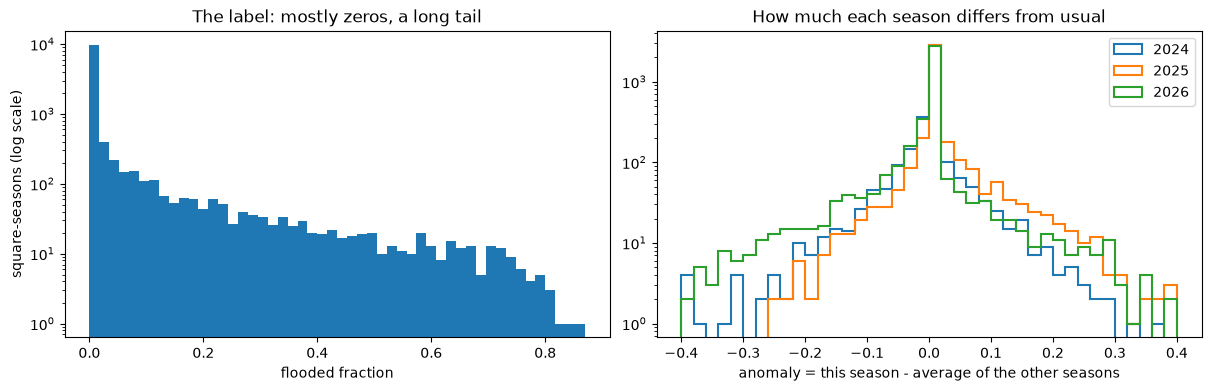

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
ax[0].hist(df[LABEL], bins=50, color="tab:blue")
ax[0].set_yscale("log"); ax[0].set_xlabel("flooded fraction"); ax[0].set_ylabel("square-seasons (log scale)")
ax[0].set_title("The label: mostly zeros, a long tail")
for s in YEARS:
    ax[1].hist(df.loc[df.season == s, "anomaly"], bins=np.linspace(-0.4, 0.4, 41), histtype="step", lw=1.5, label=str(s))
ax[1].set_yscale("log"); ax[1].set_xlabel("anomaly = this season - average of the other seasons")
ax[1].set_title("How much each season differs from usual"); ax[1].legend()
savefig(fig, "fig_label_distribution", FIG_DIR); plt.show()

## Step 2 · Validation design

Our data have a time axis (seasons) and a map, so a random split would let the model "half-remember" the answer: the same square in another season, or its next-door neighbour, sits in the training set (Week 6). We use two schemes, each answering a question someone could actually ask:

| scheme | held out | question it answers | folds | flood history allowed? |
|---|---|---|---|---|
| **A. Season hold-out** | one whole season | *"How will each square flood in a new year?"* | 3 | yes, from the training seasons only |
| **B. Region hold-out** | one whole river-basin region, all seasons, plus a 10 km buffer | *"How would a place with no flood maps behave?"* | one per region | no, the region has no history |

**Tuning without cheating.** Every setting (ridge strength, forest leaf size) is chosen by cross-validation **inside the training data**, with the squares grouped by region, so the held-out season or region never influences a choice. The test fold is scored once.

**Flood history without leakage.** In scheme A, "usual" for a training row comes from the *other* training season, never from the row itself. For test rows it is the average of both training seasons. So every row's history comes from seasons other than its own, exactly as it would in a real new season.

### The regions

Regions are HydroBASINS level-5 river basins. Small basins are merged into their nearest large neighbour, so every region has enough squares to be a meaningful test.

        squares    lat     lon  mean_flooded
region                                      
R1         1405  16.20  100.52          0.07
R2          946  16.42  102.43          0.01
R3          375  17.80  102.34          0.02
R4         1248  17.03  103.82          0.01
saved /home/tb3203/thailand-flood-ml/figures/fig_regions.png


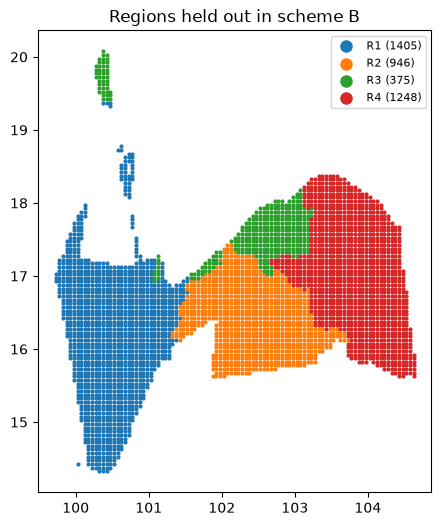

In [4]:
def make_regions(cells, level="basin_l5", min_size=300):
    c = cells.groupby(level).agg(n=("cell_id", "size"), lat=("lat", "mean"), lon=("lon", "mean"))
    big = c[c.n >= min_size]
    if len(big) < 3:                                   # fall back to the largest three
        big = c.nlargest(3, "n")
    mapping = {}
    for b, r in c.iterrows():
        if b in big.index:
            mapping[b] = b
        else:
            d = (big.lat - r.lat) ** 2 + ((big.lon - r.lon) * np.cos(np.radians(r.lat))) ** 2
            mapping[b] = d.idxmin()
    order = big.sort_values(["lon", "lat"]).index           # name regions west to east
    names = {b: f"R{i + 1}" for i, b in enumerate(order)}
    return cells[level].map(mapping).map(names)

cells = df[df.season == YEARS[0]][["cell_id", "row", "col", "lat", "lon", "basin_l5"]].reset_index(drop=True)
cells["region"] = make_regions(cells)
df = df.merge(cells[["cell_id", "region"]], on="cell_id")
REGIONS = sorted(cells.region.unique(), key=lambda r: int(r[1:]))

reg_table = cells.groupby("region").agg(squares=("cell_id", "size"), lat=("lat", "mean"), lon=("lon", "mean")).loc[REGIONS]
reg_table["mean_flooded"] = df.groupby("region")[LABEL].mean().loc[REGIONS]
print(reg_table.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 6))
for r in REGIONS:
    t = cells[cells.region == r]
    ax.scatter(t.lon, t.lat, s=4, label=f"{r} ({len(t)})")
ax.set_aspect("equal"); ax.legend(markerscale=4, fontsize=8); ax.set_title("Regions held out in scheme B")
savefig(fig, "fig_regions", FIG_DIR); plt.show()

**What to check:** about 4 to 8 regions, each with a few hundred squares or more, that follow real river basins (Ping-Nan-Chao Phraya, Chi, Mun, Mekong tributaries).

In [5]:
# Squares closer than BUFFER_KM to a held-out region are left out of training, so the model
# cannot lean on a next-door neighbour of a test square.
XY = np.c_[cells.lon * 111.32 * np.cos(np.radians(cells.lat)), cells.lat * 110.57]   # km
tree = cKDTree(XY)

def buffer_cells(test_ids):
    near = tree.query_ball_point(XY[cells.cell_id.isin(test_ids).values], r=BUFFER_KM)
    near = set(cells.cell_id.values[np.unique(np.concatenate(near))]) if len(near) else set()
    return near - set(test_ids)

def history_for(data, train_seasons, p):
    """'usual' for each row: mean label of the training seasons other than the row's own (p = label pivot)."""
    out = pd.Series(np.nan, index=data.index)
    for s in data.season.unique():
        src = [t for t in train_seasons if t != s]
        m = data.season == s
        out[m] = data.loc[m, "cell_id"].map(p[src].mean(axis=1)).values
    return out

print("buffer example:", len(buffer_cells(cells.cell_id[cells.region == REGIONS[0]])), "squares dropped around", REGIONS[0])

buffer example: 50 squares dropped around R1


## Step 3 and 4 · Baselines and models, fitted fold by fold

**Baselines** (Week 6: *a skill score without its baseline is not a result*):
- **never flooded**: predict 0 everywhere
- **one constant**: the training mean
- **elevation only**: a straight line in mean elevation, fitted on the training rows
- **usual** (scheme A only): the square's average over the training seasons, i.e. persistence of the usual pattern. Already strong, and the one to beat.

**Models**
- **Ridge regression** (Week 4), in a `Pipeline` with the scaler, so the scaler is fitted on training rows only. Tuned: penalty strength.
- **Random forest** (Week 5). Tuned: minimum leaf size and the share of features tried at each split.

In scheme A the models predict the **anomaly** (this season minus usual), with usual also given as an input, and the prediction is usual + predicted anomaly, kept between 0 and 1. A model that adds nothing then falls back to the usual baseline, so any gain over it is genuine skill at explaining *unusual* flooding. In scheme B there is no history, so the models predict the flooded fraction directly from rain, terrain and rivers.

In [6]:
MODELS = {
    "ridge":  (Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
               {"model__alpha": [1, 10, 100, 1_000, 10_000, 100_000]}),
    "forest": (RandomForestRegressor(n_estimators=N_TREES, n_jobs=-1, random_state=RANDOM_STATE),
               {"min_samples_leaf": [5, 20, 50, 100, 200], "max_features": [0.33, 0.66]} if not FAST else
               {"min_samples_leaf": [20], "max_features": [0.5]}),
}

def tune_and_fit(name, X, y, groups):
    est, grid = MODELS[name]
    k = min(4, len(np.unique(groups)))
    search = GridSearchCV(est, grid, cv=GroupKFold(n_splits=k), scoring="neg_root_mean_squared_error", n_jobs=1)
    search.fit(X, y, groups=groups)
    cv = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
    cv["mean_test_score"] *= -1
    return search.best_estimator_, search.best_params_, cv

def elevation_line(train, test, label=LABEL):
    lr = LinearRegression().fit(train[["elev_mean"]], train[label])
    return np.clip(lr.predict(test[["elev_mean"]]), 0, 1)

In [7]:
def run_season_holdout(data, label=LABEL, model_names=("ridge", "forest"), fixed_params=None):
    p = data.pivot(index="cell_id", columns="season", values=label)
    preds, fitted, tuning = [], {}, []
    for s in YEARS:
        train_seasons = [o for o in YEARS if o != s]
        tr = data[data.season.isin(train_seasons)].copy()
        te = data[data.season == s].copy()
        tr["usual"] = history_for(tr, train_seasons, p).values
        te["usual"] = te.cell_id.map(p[train_seasons].mean(axis=1)).values
        X_cols = FEATURES + ["usual"]
        out = te[["cell_id", "season", "region", "lat", "lon", "row", "col", "usual"]].copy()
        out["obs"] = te[label].values
        out["never"] = 0.0
        out["constant"] = tr[label].mean()
        out["elevation"] = elevation_line(tr, te, label)
        y_tr = tr[label] - tr["usual"]                       # the anomaly
        for name in model_names:
            if fixed_params:                                 # sensitivity runs reuse the chosen settings
                params = fixed_params[(name, s)]
                est = clone(MODELS[name][0]).set_params(**params).fit(tr[X_cols], y_tr)
            else:
                est, params, cv = tune_and_fit(name, tr[X_cols], y_tr, tr["region"])
                tuning.append(dict(scheme="A season", fold=s, model=name, best=params))
            out[name] = np.clip(te["usual"].values + est.predict(te[X_cols]), 0, 1)
            fitted[(name, s)] = (est, te[X_cols], te[label] - te["usual"], params)
        preds.append(out)
        print(f"  season {s} done ({time.time() - T0:.0f} s)")
    return pd.concat(preds, ignore_index=True), fitted, pd.DataFrame(tuning)

print("Scheme A: season hold-out")
predA, fitA, tuneA = run_season_holdout(df)

Scheme A: season hold-out
  season 2024 done (44 s)
  season 2025 done (88 s)
  season 2026 done (130 s)


In [8]:
def run_region_holdout(data, model_names=("ridge", "forest")):
    preds, fitted, tuning = [], {}, []
    for r in REGIONS:
        test_ids = set(cells.cell_id[cells.region == r])
        drop = buffer_cells(test_ids)
        tr = data[~data.cell_id.isin(test_ids | drop)]
        te = data[data.cell_id.isin(test_ids)]
        out = te[["cell_id", "season", "region", "lat", "lon", "row", "col"]].copy()
        out["obs"] = te[LABEL].values
        out["never"] = 0.0
        out["constant"] = tr[LABEL].mean()
        out["elevation"] = elevation_line(tr, te)
        for name in model_names:
            est, params, cv = tune_and_fit(name, tr[FEATURES], tr[LABEL], tr["region"])
            tuning.append(dict(scheme="B region", fold=r, model=name, best=params))
            out[name] = np.clip(est.predict(te[FEATURES]), 0, 1)
            fitted[(name, r)] = (est, te[FEATURES], te[LABEL], params)
        preds.append(out)
        print(f"  region {r} done: {len(test_ids)} test squares, {len(drop)} buffer squares dropped ({time.time() - T0:.0f} s)")
    return pd.concat(preds, ignore_index=True), fitted, pd.DataFrame(tuning)

print("Scheme B: region hold-out")
predB, fitB, tuneB = run_region_holdout(df)
tuning = pd.concat([tuneA, tuneB], ignore_index=True)
tuning.to_csv(RESULTS_DIR / "tuning_choices.csv", index=False)
tuning

Scheme B: region hold-out
  region R1 done: 1405 test squares, 50 buffer squares dropped (160 s)
  region R2 done: 946 test squares, 150 buffer squares dropped (193 s)
  region R3 done: 375 test squares, 147 buffer squares dropped (231 s)
  region R4 done: 1248 test squares, 122 buffer squares dropped (267 s)


,scheme,fold,model,best
0,A season,2024,ridge,{'model__alpha': 1000}
1,A season,2024,forest,"{'max_features': 0.33, 'min_samples_leaf': 5}"
2,A season,2025,ridge,{'model__alpha': 1000}
3,A season,2025,forest,"{'max_features': 0.66, 'min_samples_leaf': 50}"
4,A season,2026,ridge,{'model__alpha': 10000}
5,A season,2026,forest,"{'max_features': 0.66, 'min_samples_leaf': 200}"
6,B region,R1,ridge,{'model__alpha': 1000}
7,B region,R1,forest,"{'max_features': 0.33, 'min_samples_leaf': 20}"
8,B region,R2,ridge,{'model__alpha': 1000}
9,B region,R2,forest,"{'max_features': 0.33, 'min_samples_leaf': 5}"


**What to check:** the chosen settings. If the same setting wins in most folds, the choice is stable. If they jump around, the scores were probably flat, meaning the choice hardly mattered (Week 6: read `cv_results_`, not only `best_params_`).

## Step 5 · Scores

RMSE in flooded-fraction units (0.05 = 5% of a square), the mean bias (negative = predicting too little flooding), and the **skill score** against the reference baseline:

skill = 1 − MSE(model) / MSE(reference)

1 is perfect, 0 is no better than the reference, below 0 is worse. The reference is **usual** in scheme A and **one constant** in scheme B (the best baseline that is available without flood history).

In [9]:
BASE_A = ["never", "constant", "elevation", "usual"]
BASE_B = ["never", "constant", "elevation"]
MODS = ["ridge", "forest"]

def score_table(pred, fold_col, methods, ref):
    rows = []
    for f, g in pred.groupby(fold_col):
        for m in methods:
            rows.append(dict(fold=f, method=m, RMSE=rmse(g.obs, g[m]), bias=mean_bias(g.obs, g[m]),
                             skill=1 - rmse(g.obs, g[m]) ** 2 / rmse(g.obs, g[ref]) ** 2))
    return pd.DataFrame(rows)

scA = score_table(predA, "season", BASE_A + MODS, "usual")
scB = score_table(predB, "region", BASE_B + MODS, "constant")
scores = pd.concat([scA.assign(scheme="A season"), scB.assign(scheme="B region")])
scores.to_csv(RESULTS_DIR / "scores_by_fold.csv", index=False)

print("Scheme A (season hold-out): RMSE per test season")
print(scA.pivot(index="method", columns="fold", values="RMSE").loc[BASE_A + MODS].round(4).to_string())
print("\nScheme B (region hold-out): RMSE per test region")
print(scB.pivot(index="method", columns="fold", values="RMSE").loc[BASE_B + MODS].round(4).to_string())

Scheme A (season hold-out): RMSE per test season
fold         2024    2025    2026
method                           
never      0.1075  0.1236  0.1002
constant   0.1028  0.1174  0.0967
elevation  0.0991  0.1129  0.0921
usual      0.0501  0.0547  0.0715
ridge      0.0535  0.0632  0.0693
forest     0.0596  0.0643  0.0673

Scheme B (region hold-out): RMSE per test region
fold           R1      R2      R3      R4
method                                   
never      0.1746  0.0323  0.0619  0.0538
constant   0.1700  0.0482  0.0611  0.0599
elevation  0.1667  0.0408  0.0584  0.0617
ridge      0.1495  0.0356  0.0571  0.0570
forest     0.1437  0.0278  0.0520  0.0471


In [10]:
# With only 3 seasons and 4 regions, an average hides more than it shows,
# so the main tables give one column per held-out fold.
skill_A = scA.pivot(index="method", columns="fold", values="skill").loc[BASE_A + MODS].round(3)
skill_B = scB.pivot(index="method", columns="fold", values="skill").loc[BASE_B + MODS].round(3)
skill_A.to_csv(RESULTS_DIR / "skill_by_season.csv")
skill_B.to_csv(RESULTS_DIR / "skill_by_region.csv")

print("Scheme A: skill vs usual, one column per held-out season")
display(skill_A)
print("Scheme B: skill vs one constant, one column per held-out region")
display(skill_B)

# Range across folds (lowest to highest), kept for reference; no single average is reported
rng = pd.concat({"A season hold-out": scA, "B region hold-out": scB}).groupby(level=0).apply(
    lambda d: d.groupby("method")["skill"].agg(["min", "max"])).round(3)
rng.to_csv(RESULTS_DIR / "skill_range.csv")
rng

Scheme A: skill vs usual, one column per held-out season


fold,2024,2025,2026
method,,,
never,-3.604,-4.114,-0.962
constant,-3.210,-3.612,-0.825
elevation,-2.910,-3.267,-0.658
usual,0.000,0.000,0.000
ridge,-0.139,-0.339,0.063
forest,-0.415,-0.385,0.116


Scheme B: skill vs one constant, one column per held-out region


fold,R1,R2,R3,R4
method,,,,
never,-0.055,0.552,-0.026,0.193
constant,0.000,0.000,0.000,0.000
elevation,0.038,0.284,0.085,-0.059
ridge,0.226,0.455,0.126,0.095
forest,0.285,0.667,0.276,0.382


min    max
                  method                 
A season hold-out constant  -3.612 -0.825
                  elevation -3.267 -0.658
                  forest    -0.415  0.116
                  never     -4.114 -0.962
                  ridge     -0.339  0.063
                  usual      0.000  0.000
B region hold-out constant   0.000  0.000
                  elevation -0.059  0.284
                  forest     0.276  0.667
                  never     -0.055  0.552
                  ridge      0.095  0.455

**How to read this.** In scheme A the bar to clear is **usual** (skill 0 by definition). A positive skill for ridge or the forest in all three seasons means rain, terrain and rivers explain part of how a season departs from the usual pattern. A skill near 0 or below means they don't, beyond what history already says. That is a **negative result**, and an informative one. In scheme B, compare the models with the constant and elevation baselines: can physical features alone locate flooding in a basin the model has never seen? With only three seasons, each season-hold-out result is one draw, not an average behaviour. In particular, the gain in 2026 comes from a single shifted season: it shows that rain and terrain can add information when the usual pattern breaks, not that they will in every unusual year.

saved /home/tb3203/thailand-flood-ml/figures/fig_scores.png


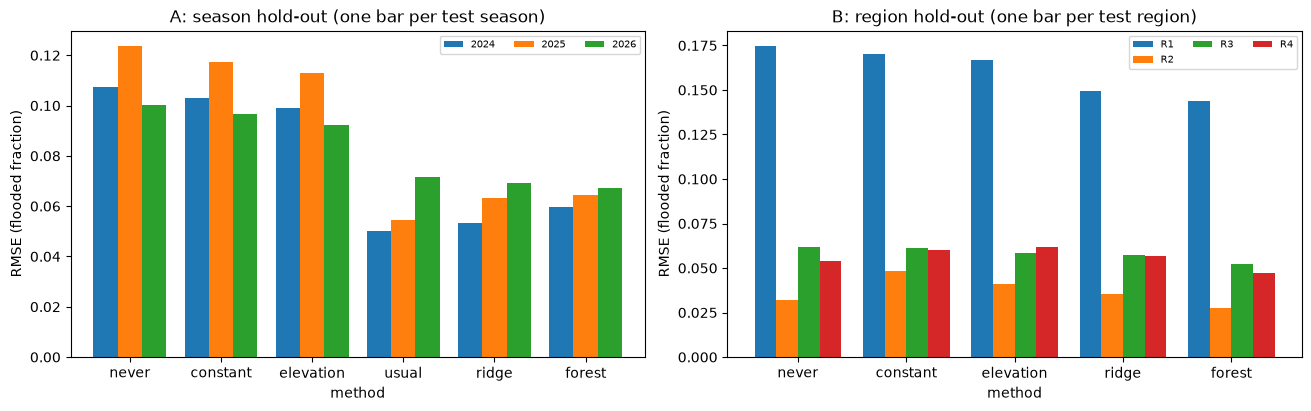

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for a, (sc, order, title) in zip(ax, [(scA, BASE_A + MODS, "A: season hold-out (one bar per test season)"),
                                      (scB, BASE_B + MODS, "B: region hold-out (one bar per test region)")]):
    pv = sc.pivot(index="method", columns="fold", values="RMSE").loc[order]
    pv.plot.bar(ax=a, rot=0, width=0.8)
    a.set_ylabel("RMSE (flooded fraction)"); a.set_title(title); a.legend(fontsize=7, ncol=3)
savefig(fig, "fig_scores", FIG_DIR); plt.show()

### How much would a random split have flattered us?

The same forest and features as scheme B, but scored with a shuffled 5-fold split of all rows, the default in most tutorials. Every test square then has itself (in other seasons) and its neighbours in the training set. The gap between the two RMSEs is the optimism a random split would have reported.

In [12]:
rf_demo = RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=20, max_features=0.5,
                                n_jobs=-1, random_state=RANDOM_STATE)
rand_pred = np.zeros(len(df))
for tr_i, te_i in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(df):
    rf_demo.fit(df.iloc[tr_i][FEATURES], df.iloc[tr_i][LABEL])
    rand_pred[te_i] = rf_demo.predict(df.iloc[te_i][FEATURES])
leak = pd.DataFrame({"split": ["random 5-fold (shuffled rows)", "region hold-out (scheme B)"],
                     "forest_RMSE": [rmse(df[LABEL], rand_pred), rmse(predB.obs, predB.forest)]}).round(4)
leak.to_csv(RESULTS_DIR / "leakage_demo.csv", index=False)
leak

,split,forest_RMSE
0,random 5-fold (shuffled rows),0.0604
1,region hold-out (scheme B),0.0918


**What to check:** the random split reports a clearly lower error. That gap is why the validation scheme matters more than the choice of model.

## Step 6 · Uncertainty

Three views, plus one honest statement:

1. **Spread across folds**: already in the summary (the range of skill across seasons and regions).
2. **Block bootstrap**: within each test season, resample the squares in 50 km blocks (10 × 10 squares) 1,000 times and recompute the RMSE difference between the forest and usual. Blocks rather than single squares, because neighbouring squares flood together. Resampling them one by one would pretend we have far more independent evidence than we do, and the interval would come out too narrow (Week 6: an interval that assumes independent errors is a floor, not the uncertainty).
3. **Label-rule sensitivity**: repeat scheme A with the looser label (a fine cell flooded if seen by **1** pass instead of 2), using the same model settings.
4. **Not quantified**: errors inside the GISTDA maps themselves (missed or false water, wet paddy fields), the unknown "dry or simply not photographed" areas, and flood depth. These are **epistemic**, and only more or better data would shrink them.

In [13]:
def block_bootstrap(g, a, b, n_boot=1000, block=10, seed=RANDOM_STATE):
    """95% interval of RMSE(a) - RMSE(b), resampling 50 km blocks of squares."""
    rng = np.random.default_rng(seed)
    blk = (g.row // block).astype(str) + "_" + (g.col // block).astype(str)
    sa = ((g[a] - g.obs) ** 2).groupby(blk).sum().values
    sb = ((g[b] - g.obs) ** 2).groupby(blk).sum().values
    n = g.groupby(blk).size().values
    idx = rng.integers(0, len(n), size=(n_boot, len(n)))
    diff = np.sqrt(sa[idx].sum(1) / n[idx].sum(1)) - np.sqrt(sb[idx].sum(1) / n[idx].sum(1))
    return np.percentile(diff, [2.5, 50, 97.5])

boot = []
for s, g in predA.groupby("season"):
    for m in MODS:
        lo, mid, hi = block_bootstrap(g, m, "usual")
        boot.append(dict(season=s, model=m, diff_median=mid, ci_low=lo, ci_high=hi,
                         verdict="better than usual" if hi < 0 else "worse than usual" if lo > 0 else "no clear difference"))
boot = pd.DataFrame(boot).round(4)
boot.to_csv(RESULTS_DIR / "bootstrap_vs_usual.csv", index=False)
boot

,season,model,diff_median,ci_low,ci_high,verdict
0,2024,ridge,0.0034,-0.0006,0.0075,no clear difference
1,2024,forest,0.0094,0.0025,0.0178,worse than usual
2,2025,ridge,0.0085,0.0041,0.0131,worse than usual
3,2025,forest,0.0095,0.0054,0.0137,worse than usual
4,2026,ridge,-0.0023,-0.0036,-0.0010,better than usual
5,2026,forest,-0.0043,-0.0066,-0.0017,better than usual


**What to check:** an interval that lies entirely below 0 means the model beats usual in that season, beyond what chance resampling would produce. An interval that crosses 0 means we cannot tell them apart.

In [14]:
fixed = {(m, s): fitA[(m, s)][3] for m in MODS for s in YEARS}
pred1, _, _ = run_season_holdout(df, label="flooded_frac_1pass", fixed_params=fixed)
sens = pd.concat({"2-pass rule (main)": scA.pivot(index="method", columns="fold", values="RMSE"),
                  "1-pass rule": score_table(pred1, "season", BASE_A + MODS, "usual").pivot(index="method", columns="fold", values="RMSE")},
                 axis=1).loc[BASE_A + MODS].round(4)
sens.to_csv(RESULTS_DIR / "label_sensitivity.csv")
sens

  season 2024 done (280 s)
  season 2025 done (282 s)
  season 2026 done (284 s)


2-pass rule (main)                 1-pass rule                
fold                    2024    2025    2026        2024    2025    2026
method                                                                  
never                 0.1075  0.1236  0.1002      0.1284  0.1407  0.1189
constant              0.1028  0.1174  0.0967      0.1210  0.1315  0.1134
elevation             0.0991  0.1129  0.0921      0.1156  0.1254  0.1070
usual                 0.0501  0.0547  0.0715      0.0602  0.0651  0.0858
ridge                 0.0535  0.0632  0.0693      0.0646  0.0735  0.0829
forest                0.0596  0.0643  0.0673      0.0644  0.0729  0.0798

**What to check:** whether the ranking of methods stays the same under both rules. Errors are larger with the 1-pass rule because more squares count as flooded. If the forest beats usual under one rule but not the other, the result depends on how we drew the label, and the paper must say so.

## Step 7 · Floods as events: misses and false alarms

For anyone acting on these maps, the two mistakes don't cost the same:
- a **miss** (the square floods, the model said it wouldn't): people and crops unprepared, the costly mistake
- a **false alarm** (the model said flood, it stayed dry): wasted preparation, and lost trust over time

We call a square-season **flooded** if at least 5% of it is underwater, and treat each method's prediction as a flood score. Floods are rare, so we use **precision-recall** curves, not ROC (plume-detection notebook). The reference line is the **base rate**, the score of random guessing. *Recall* = share of real floods caught; *precision* = share of flood warnings that were right.

saved /home/tb3203/thailand-flood-ml/figures/fig_precision_recall.png


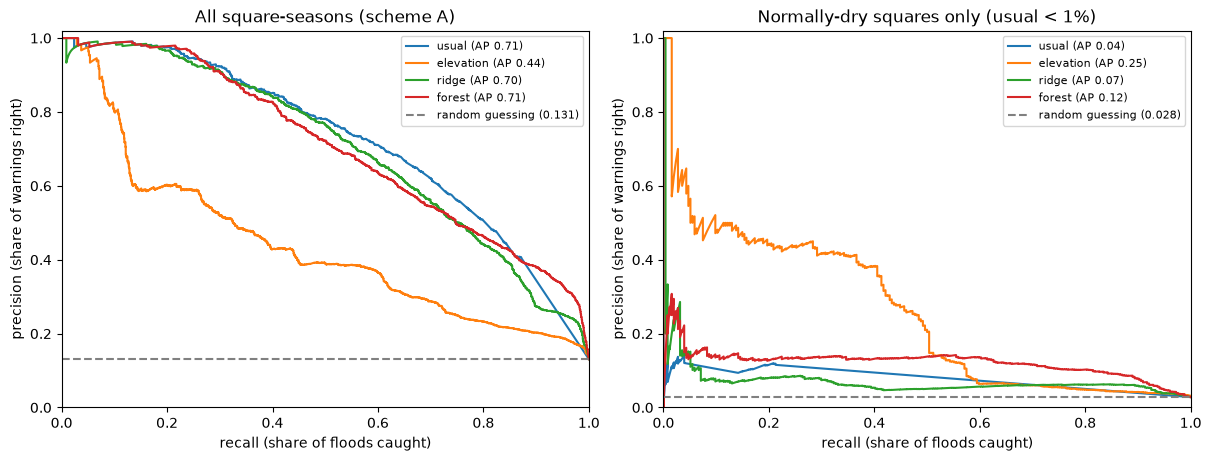

,subset,method,AP,base_rate
0,All square-seasons (scheme A),usual,0.706,0.131
1,All square-seasons (scheme A),elevation,0.439,0.131
2,All square-seasons (scheme A),ridge,0.701,0.131
3,All square-seasons (scheme A),forest,0.705,0.131
4,Normally-dry squares only (usual < 1%),usual,0.044,0.028
5,Normally-dry squares only (usual < 1%),elevation,0.254,0.028
6,Normally-dry squares only (usual < 1%),ridge,0.073,0.028
7,Normally-dry squares only (usual < 1%),forest,0.124,0.028


In [15]:
ev = predA.assign(flood=(predA.obs >= EVENT).astype(int))
base_rate = ev.flood.mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
rows = []
for a, (subset, title) in zip(ax, [(ev, "All square-seasons (scheme A)"),
                                   (ev[ev.usual < 0.01], "Normally-dry squares only (usual < 1%)")]):
    br = subset.flood.mean()
    for m in ["usual", "elevation"] + MODS:
        if subset.flood.sum() == 0:
            continue
        p, r, _ = precision_recall_curve(subset.flood, subset[m])
        ap = average_precision_score(subset.flood, subset[m])
        a.plot(r, p, label=f"{m} (AP {ap:.2f})")
        rows.append(dict(subset=title, method=m, AP=ap, base_rate=br))
    a.axhline(br, ls="--", color="gray", label=f"random guessing ({br:.3f})")
    a.set_xlabel("recall (share of floods caught)"); a.set_ylabel("precision (share of warnings right)")
    a.set_title(title); a.legend(fontsize=8); a.set_xlim(0, 1); a.set_ylim(0, 1.02)
savefig(fig, "fig_precision_recall", FIG_DIR); plt.show()
ap_table = pd.DataFrame(rows).round(3)
ap_table.to_csv(RESULTS_DIR / "event_average_precision.csv", index=False)
ap_table

In [16]:
# Two operating points: what a warning rule would actually do at a given threshold on the predicted fraction
op = []
for m in ["usual"] + MODS:
    for thr in [0.02, 0.05, 0.10]:
        warn = ev[m] >= thr
        tp, fp, fn = int((warn & (ev.flood == 1)).sum()), int((warn & (ev.flood == 0)).sum()), int((~warn & (ev.flood == 1)).sum())
        sur = ev.usual < 0.01
        op.append(dict(method=m, threshold=thr, recall=tp / max(tp + fn, 1), precision=tp / max(tp + fp, 1),
                       misses=fn, false_alarms=fp,
                       surprise_floods_caught=int((warn & (ev.flood == 1) & sur).sum()),
                       surprise_floods_total=int(((ev.flood == 1) & sur).sum())))
op = pd.DataFrame(op).round(3)
op.to_csv(RESULTS_DIR / "event_operating_points.csv", index=False)
op

,method,threshold,recall,precision,misses,false_alarms,surprise_floods_caught,surprise_floods_total
0,usual,0.02,0.789,0.516,329,1157,0,254
1,usual,0.05,0.678,0.642,503,590,0,254
2,usual,0.10,0.540,0.747,718,286,0,254
3,ridge,0.02,0.862,0.361,216,2387,81,254
4,ridge,0.05,0.714,0.542,446,942,18,254
5,ridge,0.10,0.554,0.706,697,361,1,254
6,forest,0.02,0.859,0.415,221,1893,88,254
7,forest,0.05,0.688,0.551,487,877,16,254
8,forest,0.10,0.529,0.694,735,364,5,254


**How to read this.** Lowering the threshold catches more floods (fewer misses) at the price of more false alarms. Which threshold is right depends on the cost of each mistake, not on the statistics. If a miss costs, say, three times a false alarm, choose the threshold that minimises 3 × misses + false alarms. The **usual** baseline can never warn for a normally-dry square, so `surprise_floods_caught` is where a physical model has to earn its keep.

## Step 8 · What did the model learn, and where does it fail?

### 8a · Permutation importance

For each held-out fold, shuffle one feature at a time in the **test** data and measure how much the error grows. Unlike the forest's built-in importance, this is measured on unseen data and doesn't favour features with many distinct values (Week 5). Features that move together (for example elevation and slope) share their importance, so a low score for one of them doesn't mean it is physically irrelevant.

In [ ]:
def perm_imp(fitted, model="forest", n_repeats=5):
    rows = []
    for (m, fold), (est, X, y, _) in fitted.items():
        if m != model:
            continue
        r = permutation_importance(est, X, y, scoring="neg_root_mean_squared_error",
                                   n_repeats=n_repeats, random_state=RANDOM_STATE, n_jobs=-1)
        rows.append(pd.Series(r.importances_mean, index=X.columns, name=fold))
    return pd.concat(rows, axis=1)

impA, impB = perm_imp(fitA), perm_imp(fitB)
imp = pd.DataFrame({"A season hold-out": impA.mean(1), "B region hold-out": impB.mean(1)}).fillna(0)
imp.to_csv(RESULTS_DIR / "permutation_importance.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
for a, col in zip(ax, imp.columns):
    top = imp[col].sort_values().tail(12)
    a.barh(top.index, top.values)
    a.set_title(f"{col}: forest"); a.set_xlabel("increase in RMSE when shuffled")
savefig(fig, "fig_permutation_importance", FIG_DIR); plt.show()

**What to check:** in scheme A, `usual` should dominate. Physically, the real question is what comes **after** it. If rain or upstream rain appear, the model is using this season's weather to adjust the usual pattern, which is what we hoped. In scheme B, terrain and river distance should lead: without history, the model can only find where water collects.

### 8b · Do the learned effects agree with physics?

Partial dependence shows how the forest's prediction changes, on average, as one feature varies while the others are held as they are. Physics says: more rain → more flooding; higher ground relative to its surroundings → less flooding.

In [ ]:
est, X_te, _, _ = fitB[("forest", REGIONS[0])]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), layout="constrained")
PartialDependenceDisplay.from_estimator(est, X_te, ["rel_height", "dist_riv_10k_km", "up_rain_window", "rain_window"],
                                        ax=ax, grid_resolution=30)
fig.suptitle(f"Region hold-out forest (test region {REGIONS[0]}): average effect of four features on the predicted flooded fraction")
savefig(fig, "fig_partial_dependence", FIG_DIR); plt.show()

**What to check:** a falling curve for relative height and river distance, and a rising (or flat) one for rain. A curve with the wrong slope is a warning sign: the model may be using that feature as a stand-in for location rather than for physics.

### 8c · Where does it fail? Errors by kind of square

Averages hide the cases that matter (the ozone example: fine on ordinary days, ten ppb low on the worst ones). We split the test squares by what they usually do:

In [ ]:
def kind(r):
    if r.usual >= EVENT:          return "1 usually floods"
    if r.obs >= EVENT:            return "2 surprise flood"
    if r.obs > 0:                 return "3 a little water"
    return "4 dry"
predA["kind"] = predA.apply(kind, axis=1)

cat = []
for (s, k), g in predA.groupby(["season", "kind"]):
    cat.append(dict(season=s, kind=k, squares=len(g),
                    RMSE_usual=rmse(g.obs, g.usual), RMSE_forest=rmse(g.obs, g.forest),
                    bias_usual=mean_bias(g.obs, g.usual), bias_forest=mean_bias(g.obs, g.forest)))
cat = pd.DataFrame(cat).round(4)
cat.to_csv(RESULTS_DIR / "errors_by_kind.csv", index=False)
cat

**What to check:** the **bias** column for surprise floods. Both methods will be strongly negative there (they predict too little), and the question is whether the forest closes part of the gap. Big floods being under-predicted is the classic failure of models trained on squared error, and it is the most important limitation for anyone using these maps.

In [ ]:
# Does the error depend on how often a square was photographed? (the coverage limitation, in numbers)
tp = df[["cell_id", "season", "times_photographed"]]
cov = predA.merge(tp, on=["cell_id", "season"])
cov["abs_err_forest"] = (cov.forest - cov.obs).abs()
cov["coverage_tercile"] = pd.qcut(cov.times_photographed, 3, labels=["least photographed", "middle", "most photographed"])
cov.groupby("coverage_tercile", observed=True).agg(squares=("obs", "size"), mean_obs=("obs", "mean"),
                                                   mean_abs_error=("abs_err_forest", "mean")).round(4)

**What to check:** if the most-photographed squares show more flooding and larger errors, part of what we call flooding is really *being looked at more often*. That belongs in the limitations.

In [ ]:
# Extrapolation: trees cannot predict beyond what they saw in training (Week 5, demand-forest notebook)
ext = []
for s in YEARS:
    tr, te = df[df.season != s], df[df.season == s]
    for f in ["rain_window", "rain_early", "max_7d", "up_rain_window", "rain_oct"]:
        outside = ((te[f] < tr[f].min()) | (te[f] > tr[f].max())).mean()
        ext.append(dict(test_season=s, feature=f, share_outside_training_range=round(outside, 3)))
pd.DataFrame(ext).pivot(index="feature", columns="test_season", values="share_outside_training_range")

**What to check:** 2026 was the driest season, so some of its squares may lie outside the 2024 to 2025 rain range. Where they do, the forest can only repeat the nearest training values, while ridge can extrapolate (for better or worse).

### 8d · Error map for the hardest season (2026)

Green = flood caught, red = false alarm, blue = missed flood, grey = correctly dry. Missed floods that cluster in one area point to something the inputs can't see: a dam release, a dike, or a canal network.

In [ ]:
g = predA[predA.season == 2026]
fig, ax = plt.subplots(1, 4, figsize=(20, 6), sharey=True, layout="constrained")
for a, col, title in zip(ax[:3], ["obs", "usual", "forest"], ["observed 2026", "usual (average of 2024 and 2025)", "forest prediction"]):
    sc = a.scatter(g.lon, g.lat, c=g[col], s=4, cmap="Blues", vmin=0, vmax=0.3)
    a.set_title(title); a.set_aspect("equal")
fig.colorbar(sc, ax=ax[:3], shrink=0.6, label="flooded fraction")
obs_f, pred_f = g.obs >= EVENT, g.forest >= EVENT
colors = np.select([obs_f & pred_f, ~obs_f & pred_f, obs_f & ~pred_f], ["tab:green", "tab:red", "tab:blue"], "0.85")
ax[3].scatter(g.lon, g.lat, c=colors, s=4); ax[3].set_aspect("equal")
ax[3].set_title(f"forest at {EVENT:.0%}: hits {int((obs_f & pred_f).sum())}, false alarms {int((~obs_f & pred_f).sum())}, misses {int((obs_f & ~pred_f).sum())}")
savefig(fig, "fig_error_map_2026", FIG_DIR); plt.show()

## Step 9 · Key numbers for the paper

Everything below is also saved in `results/`. The paper quotes these numbers, so rerunning this notebook regenerates every number in it.

In [ ]:
best = lambda sc, m: sc[sc.method == m].set_index("fold")["skill"].round(3).to_dict()
print("Scheme A, skill vs usual, per test season:")
for m in MODS:
    print(f"  {m:7s}", best(scA, m))
print("Scheme B, skill vs one constant, per test region:")
for m in MODS + ["elevation"]:
    print(f"  {m:9s}", best(scB, m))
print("\nRandom split vs region hold-out (forest RMSE):", leak.forest_RMSE.tolist())
print("Event view: average precision, all squares:", ap_table[ap_table.subset.str.startswith("All")].set_index("method").AP.to_dict(),
      "| base rate:", round(base_rate, 3))
print(f"\nTotal run time: {(time.time() - T0) / 60:.1f} min")

## Summary

The tables and figures above answer the rubric items in order: question and label (step 1), a validation design that matches the two real questions (step 2), baselines under the same splits (step 3), tuned models (step 4), honest scores and the random-split comparison (step 5), uncertainty (step 6), the consequence view (step 7), and interpretation and failure modes (step 8).

**Save the work:**
```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 04: main analysis with baselines, two validation schemes, uncertainty, interpretation"
git push
```